[instructions & rubric](https://course.ccs.neu.edu/ds4400f26-higger/learn/puzzle_problems.html)

# Puzzle: Earthquake

An earthquake starts somewhere beneath a region and its shock wave spreads
out through the ground at about 6 km/s (a typical speed for the first,
fastest wave through the upper crust). Seismograph stations at known
positions each record how many seconds after the quake started they felt
the shaking. Their timings are a little noisy.

`Earthquake` (in `earthquake.py`) simulates one quake: `quake.x` holds the
station positions (n by 2, km), `quake.t` the delay each station recorded
(n, seconds) and `quake.speed` the wave speed (km/s).
`quake.evaluate(y_hat)` returns the mean squared error (km^2) of a guess
`y_hat` at the epicenter (x, y). Anything on a quake whose name starts with
an underscore (e.g. `quake._y`) is the hidden truth: peeking at it is
cheating.

- Where did the quake start? Find the epicenter whose predicted delays best
  match the recorded ones.
- How far off is your estimate on a typical quake (default settings: 10
  stations, 0.2 s timing noise)? When does it go badly wrong? Arguments to
  `Earthquake(...)` change the number of stations, their spacing and the
  timing noise.
- For fun, post your estimator to the
  [leaderboard](https://matthigger.github.io/ml_puzzle/where_start/)
  with class code `where-hcee-nt7q-h9ky` (no effect on your grade).


## Summary

Our method locates an earthquake from how long the shaking took to reach each of 10 stations. It finds the spot that best explains those delays. On 2,000 simulated earthquakes it had never seen, it typically pins the epicenter within 0.7 km, and 99% of the time within 2.4 km, versus 35 km for guessing the middle of the stations. It goes badly wrong when fewer than 5 stations are compared, and its error grows with the square of the timing noise.

## Approach

Each delay times the wave speed says how far the epicenter is from that station, so the epicenter sits where the stations' distance circles nearly cross. We compare:

- **centroid:** the stations' average position (the prompt's baseline)
- **OLS:** subtract one station's circle equation from the others, leaving a linear system solved in one step; its fast but amplifies noise
- **nonlinear least squares (LS):** find the point whose predicted delays most closely match the recorded ones, starting from 12 places and keeping the best fit 

We assume the waves move in straight lines at the known speed, a known start time and independent timing errors. We test on earthquakes that have not been seen before.

    centroid misses by 15.99 km
         OLS misses by  0.36 km
nonlinear LS misses by  0.49 km


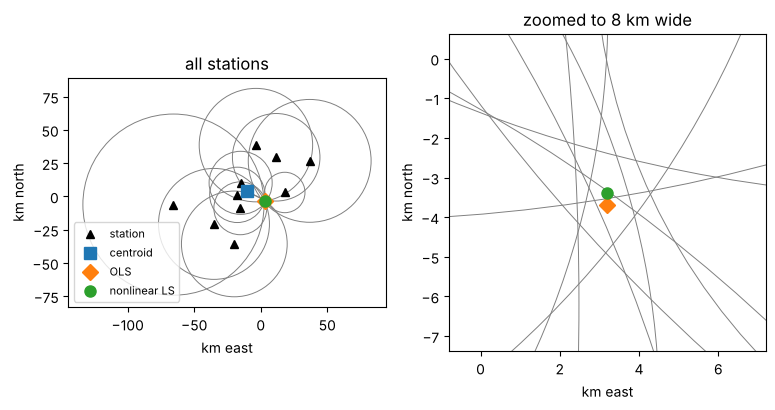

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from earthquake import Earthquake
from quake_helpers import centroid, linear, fit, run, sweep, summary, plot_quake

# the prompt's quake: estimate from public data only, score with evaluate
quake = Earthquake(seed=0)
est = {name: f(quake.x, quake.t, quake.speed) for name, f in
       [('centroid', centroid), ('OLS', linear), ('nonlinear LS', fit)]}
for name, y_hat in est.items():
    print(f'{name:>12} misses by {np.sqrt(2 * quake.evaluate(y_hat)):5.2f} km')
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
plot_quake(axes[0], quake, est)
plot_quake(axes[1], quake, est, half_width=4)
axes[0].set_title('all stations'); axes[1].set_title('zoomed in')
axes[0].legend(loc='lower left', fontsize=8);

Noise keeps the circles from meeting at one point (right); both least-squares methods land in the gap, the centroid far off. OLS wins on this quake, so we test 2,000 more next.

    centroid: mean   878.579   median 620.688   99th pct  4332.947
         OLS: mean     1.611   median   0.740   99th pct    13.101
nonlinear LS: mean     0.414   median   0.235   99th pct     2.790


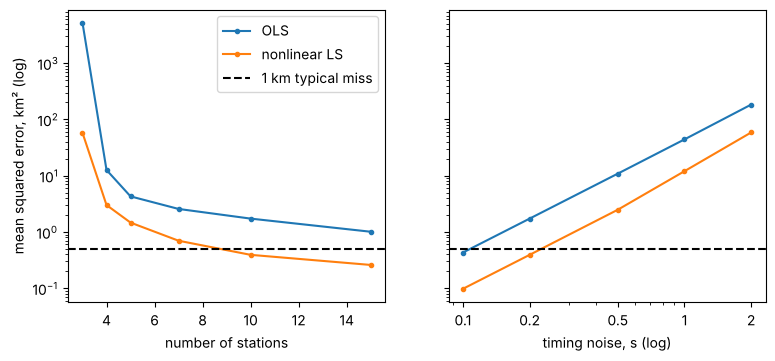

In [ ]:
methods = {'centroid': centroid, 'OLS': linear, 'nonlinear LS': fit}
summary(run(range(5000, 7000), methods))  # mse, km^2, on 2,000 unseen quakes

n_all, sd_all, seeds = [3, 4, 5, 7, 10, 15], [.1, .2, .5, 1, 2], range(7000, 7200)
by_n = sweep('n', n_all, seeds, names=('linear', 'fit'))
by_sd = sweep('noise_sd', sd_all, seeds, names=('linear', 'fit'))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, vals, res, xlabel in [(axes[0], n_all, by_n, 'number of stations'),
                              (axes[1], sd_all, by_sd, 'timing noise, s (log)')]:
    ax.plot(vals, res['linear'], '.-', label='OLS')
    ax.plot(vals, res['fit'], '.-', label='nonlinear LS')
    ax.axhline(.5, color='k', linestyle='--', label='1 km typical miss')
    ax.set(xlabel=xlabel, yscale='log')
axes[1].set(xscale='log', xticks=sd_all, xticklabels=sd_all)
axes[0].set_ylabel('mean squared error, km² (log)'); axes[0].legend();

Nonlinear LS beats OLS 3 to 90-fold everywhere; it keeps a typical miss under 1 km only with at least 10 stations and noise no larger than the default 0.2 s; below 5 stations, the delays can fit two crossing points and its error explodes.